In [1]:
import pandas as pd

dataset_labels = {
    'CHESS 2025-11-05': 'chess_20251105',
    'ALS 2026-04-23': 'als_20260423',
}

data = {}
for key, label in dataset_labels.items():
    fn = f'source_data/fig6_iso_aniso_{label}.csv'
    print('loading',fn)
    data[key] = pd.read_csv(fn).set_index('s')

loading source_data/fig6_iso_aniso_chess_20251105.csv
loading source_data/fig6_iso_aniso_als_20260423.csv


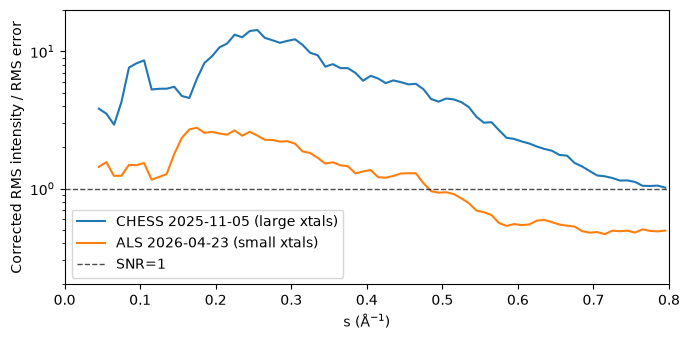

In [2]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 1, figsize=(7,3.5))

dataset_legends = {
    'CHESS 2025-11-05': 'CHESS 2025-11-05 (large xtals)',
    'ALS 2026-04-23': 'ALS 2026-04-23 (small xtals)',
}

for key, df in data.items():
    snr = df['irmscorr'] / df['intensity_error_rms']
    snr.plot(ax=ax,label=dataset_legends[key])
ax.axhline(1, color='k', ls='--', lw=1, alpha=0.7, label='SNR=1')
ax.legend()
ax.set_xlim(0, 0.8)
ax.set_ylim(0.2, 20)
ax.set_yscale('log')
ax.set_xlabel("s (Å$^{-1}$)")
ax.set_ylabel('Corrected RMS intensity / RMS error')

plt.tight_layout()

plt.savefig("export/fig6_snr.svg", transparent=True, bbox_inches="tight")
plt.savefig("export/fig6_snr.pdf", transparent=True, bbox_inches="tight")
plt.savefig("export/fig6_snr.png", transparent=True, bbox_inches="tight", dpi=300)